# Causal-Audit walkthrough

Follow the process before you select a discovery method:

1. Inspect the raw series and timestamps.
2. Run the assumption audit.
3. Read the recommendation or abstention.
4. Check the diagnostic evidence.
5. Interpret the risk scores and figures.
6. Adjust the audit configuration when needed.
7. Investigate violations; assess any preprocessing and audit again.
8. Apply the workflow to your own data.
9. Save the evidence, settings, and environment.

The framework runs **diagnostics → risk scores → recommendation**. We read the decision first and then examine its evidence. Preprocessing and discovery are separate tasks.

This notebook runs on its own and saves to `walkthrough_output/`. For the short complete run, see the [quickstart](quickstart.ipynb).

## Setup

From the repository root, install into your notebook environment:

```bash
python -m pip install -e ".[viz]" ipykernel
python -m ipykernel install --user --name causal-audit --display-name "Python (causal-audit)"
```

Select **Python (causal-audit)**. The import path below identifies the implementation.

Use a numeric `DataFrame` with a chronological, unique `DatetimeIndex`. Keep gaps as `NaN`; filling or deleting them changes the evidence. Several diagnostics need at least 50 observed values per variable.

The example has four variables and 600 daily observations drawn from a VAR(1) with Gaussian innovations.

In [1]:
%matplotlib inline
import json
import warnings
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

import causal_audit
from causal_audit import RiskAwareGatekeeper

# Hide only known tuple-return API deprecation notices; keep audit warnings visible.
warnings.filterwarnings(
    "ignore", message=r"(adfuller|kpss) currently returns a plain tuple",
    category=FutureWarning, module=r"causal_audit\.a_auditor",
)

# Relative output directory so the notebook is portable.
output_dir = Path("examples") / "walkthrough_output" if Path("examples").is_dir() else Path("walkthrough_output")
print("Installed distribution:", version("causal-audit"))


Installed distribution: 0.3.1


## 1. Inspect the raw data

Check sampling intervals, gaps, scales, drift, and abrupt changes, and keep the original observations. The plot below shows a stable process with known equations.

,X0,X1,X2,X3
2020-01-01,-1.316163,-2.014380,-1.559404,0.140185
2020-01-02,-1.394214,-0.158569,-1.238050,-0.367075
2020-01-03,-0.989390,-1.471526,-0.185814,-0.624021
2020-01-04,-1.200550,-0.167038,-0.136321,0.065176
2020-01-05,1.113216,-1.352669,0.420373,-0.476895


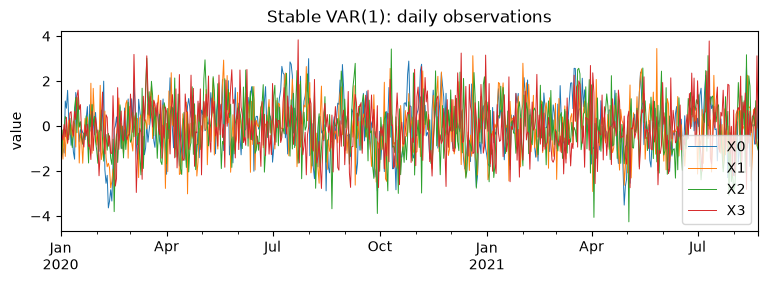

In [2]:
A_clean = np.array([
    [0.5, 0.0, 0.0, 0.0],
    [0.6, 0.0, 0.0, 0.0],
    [0.0, 0.6, 0.0, 0.0],
    [0.0, 0.0, 0.5, 0.0],
])


def simulate_var(A, seed=0, n=600, burn_in=200):
    rng = np.random.default_rng(seed)
    x = np.zeros((n + burn_in, 4))
    for t in range(1, len(x)):
        x[t] = A @ x[t - 1] + rng.normal(size=4)
    return pd.DataFrame(
        x[burn_in:], columns=["X0", "X1", "X2", "X3"],
        index=pd.date_range("2020-01-01", periods=n, freq="D"),
    )


df = simulate_var(A_clean)
display(df.head())
ax = df.plot(figsize=(9, 2.6), linewidth=0.7, title="Stable VAR(1): daily observations")
ax.set_ylabel("value")
display(ax.figure)
plt.close(ax.figure)

## 2. Run the complete audit

The VAR is stable: its largest eigenvalue is 0.5. After discarding 200 initial steps it contains the lagged chain `X0 → X1 → X2 → X3`.

One call runs all three stages and saves six diagnostic figures, tables, and reports. Keep warnings visible.

In [3]:
gatekeeper = RiskAwareGatekeeper(random_seed=42)
result = gatekeeper.analyze(data=df, output_dir=str(output_dir / "clean"))

Phase 1/3: Running assumption audit...


Phase 2/3: Quantifying risks...
Phase 3/3: Generating recommendation...
Generating figures...


  ✓ Generated 6 figures (PDF + PNG, 300 DPI)

✓ Analysis complete! Results saved to walkthrough_output/clean
  - Decision: RECOMMEND
  - Recommended method: PCMCI+
  - Confidence: 85.00%


## 3. Read the decision and configuration

Read the rationale together with the proposed settings. A recommendation is advice; an abstention means the policy cannot recommend a method for the current inputs. Confidence is a policy score, not graph accuracy.

The display below handles both outcomes.

In [4]:
def show_decision(audit_result):
    policy = audit_result["policy"]
    print("Decision:", policy.decision.upper())
    if policy.decision == "recommend":
        print("Proposed method:", policy.recommended_method)
        if policy.confidence is not None:
            print(f"Confidence (policy score): {policy.confidence:.0%}")
        print("Proposed configuration:")
        print(json.dumps(policy.method_config, indent=2))
    print("Reason codes:", ", ".join(policy.policy_reason_codes))
    display(Markdown("**Rationale**\n\n" + audit_result["scorecard"].rationale))


show_decision(result)

Decision: RECOMMEND
Proposed method: PCMCI+
Confidence (policy score): 85%
Proposed configuration:
{
  "pcmci": {
    "enabled": true,
    "test_method": "parcorr",
    "allow_contemporaneous": true
  },
  "granger": {
    "enabled": true,
    "note": "fast linear baseline"
  },
  "method": "PCMCI+",
  "tau_max": 12,
  "alpha": 0.05,
  "fdr_method": "fdr_bh"
}
Reason codes: RECOMMEND, ROBUST_METHOD_SELECTED


**Rationale**

Low structural risk profile: PCMCI+(ParCorr) is the linear default. The audit does not establish the non-Gaussian innovations required by VARLiNGAM. Check stationarity, causal sufficiency and the chosen lag horizon separately. IrregularityRisk=0.18; gaps require explicit handling before discovery.

## 4. Inspect the diagnostic evidence

For this linear Gaussian process, PCMCI+ with ParCorr is a plausible choice. It also assumes stationarity, causal sufficiency, and the Markov and faithfulness conditions. See [Tigramite's assumptions](https://github.com/jakobrunge/tigramite#overview).

ADF tests a unit root, while this audit's KPSS test uses trend stationarity as its null. Small p values reject different hypotheses. KPSS values can reach tabulated bounds, and a reported ADF zero reflects a numerical limit.

Effective sample size (ESS) comes from an ACF approximation. The lag suggestion measures how fast dependence decays, not the longest causal delay; the policy sets its horizon separately. Here one lag is one day.

In [5]:
evidence = result["audit_evidence"]
rows = []
for variable in df.columns:
    stationarity = evidence.diagnostics["stationarity"][variable]
    rows.append({
        "variable": variable,
        "ADF p": stationarity["adf"]["pvalue"],
        "KPSS p": stationarity["kpss"]["pvalue"],
        "missing (%)": 100 * evidence.diagnostics["irregularity"]["per_variable"][variable]["missing_rate"],
        "ESS (approx.)": evidence.t_eff[variable],
    })
diagnostic_table = pd.DataFrame(rows).set_index("variable")
display_table = diagnostic_table.copy()
display_table["ADF p"] = display_table["ADF p"].map(lambda p: "0 (limit)" if p == 0 else f"{p:.2g}")
display_table["KPSS p"] = display_table["KPSS p"].map(lambda p: f"{p:.2g}")
display_table["missing (%)"] = display_table["missing (%)"].round(1)
display_table["ESS (approx.)"] = display_table["ESS (approx.)"].round().astype(int)
display(display_table)
print("ACF-based lag suggestion:", evidence.safe_tau_max["data_driven"])
print("Policy lag horizon:", result["policy"].method_config["tau_max"])

,ADF p,KPSS p,missing (%),ESS (approx.)
variable,,,,
X0,1.3e-20,0.1,0.0,178
X1,7.3e-22,0.1,0.0,377
X2,1.1e-22,0.1,0.0,600
X3,0 (limit),0.1,0.0,600


ACF-based lag suggestion: 2
Policy lag horizon: 12


## 5. Read the risk profile

The implementation returns six diagnostic scores. The [paper](https://arxiv.org/abs/2604.02488) evaluates four calibrated dimensions, so that evidence does not cover all six outputs.

Bounds come from diagnostic perturbations or heuristic overrides, not from established posterior coverage. Low scores cannot exclude hidden causes, and some mappings keep a nonzero baseline even with complete data.

In [6]:
risk_labels = {
    "NonstationarityRisk": "Nonstationarity",
    "IrregularityRisk": "Irregularity",
    "PersistenceRisk": "Persistence",
    "ConfoundingRisk": "Confounding proxy",
    "NonlinearityRisk": "Nonlinearity",
    "SeasonalityRisk": "Spectral/trend proxy",
}
profile = result["risk_profile"]
risk_table = pd.DataFrame(profile.risks).T.rename(index=risk_labels)
risk_table.columns = ["score", "approx. lower bound", "approx. upper bound"]
display(risk_table.round(3))

,score,approx. lower bound,approx. upper bound
Nonstationarity,0.223,0.102,0.344
Irregularity,0.182,0.121,0.244
Persistence,0.050,0.024,0.075
Confounding proxy,0.040,0.022,0.058
Nonlinearity,0.182,0.092,0.273
Spectral/trend proxy,0.132,0.059,0.206


### Audit summary

Panels show the standardized series, the scores with approximate bounds, the ACF and ESS, prediction gain, and the policy. Positive gain favors the random forest over linear autoregression; negative gain favors the linear model. This measures prediction, not causal form.

The same figure is saved as PNG and PDF.

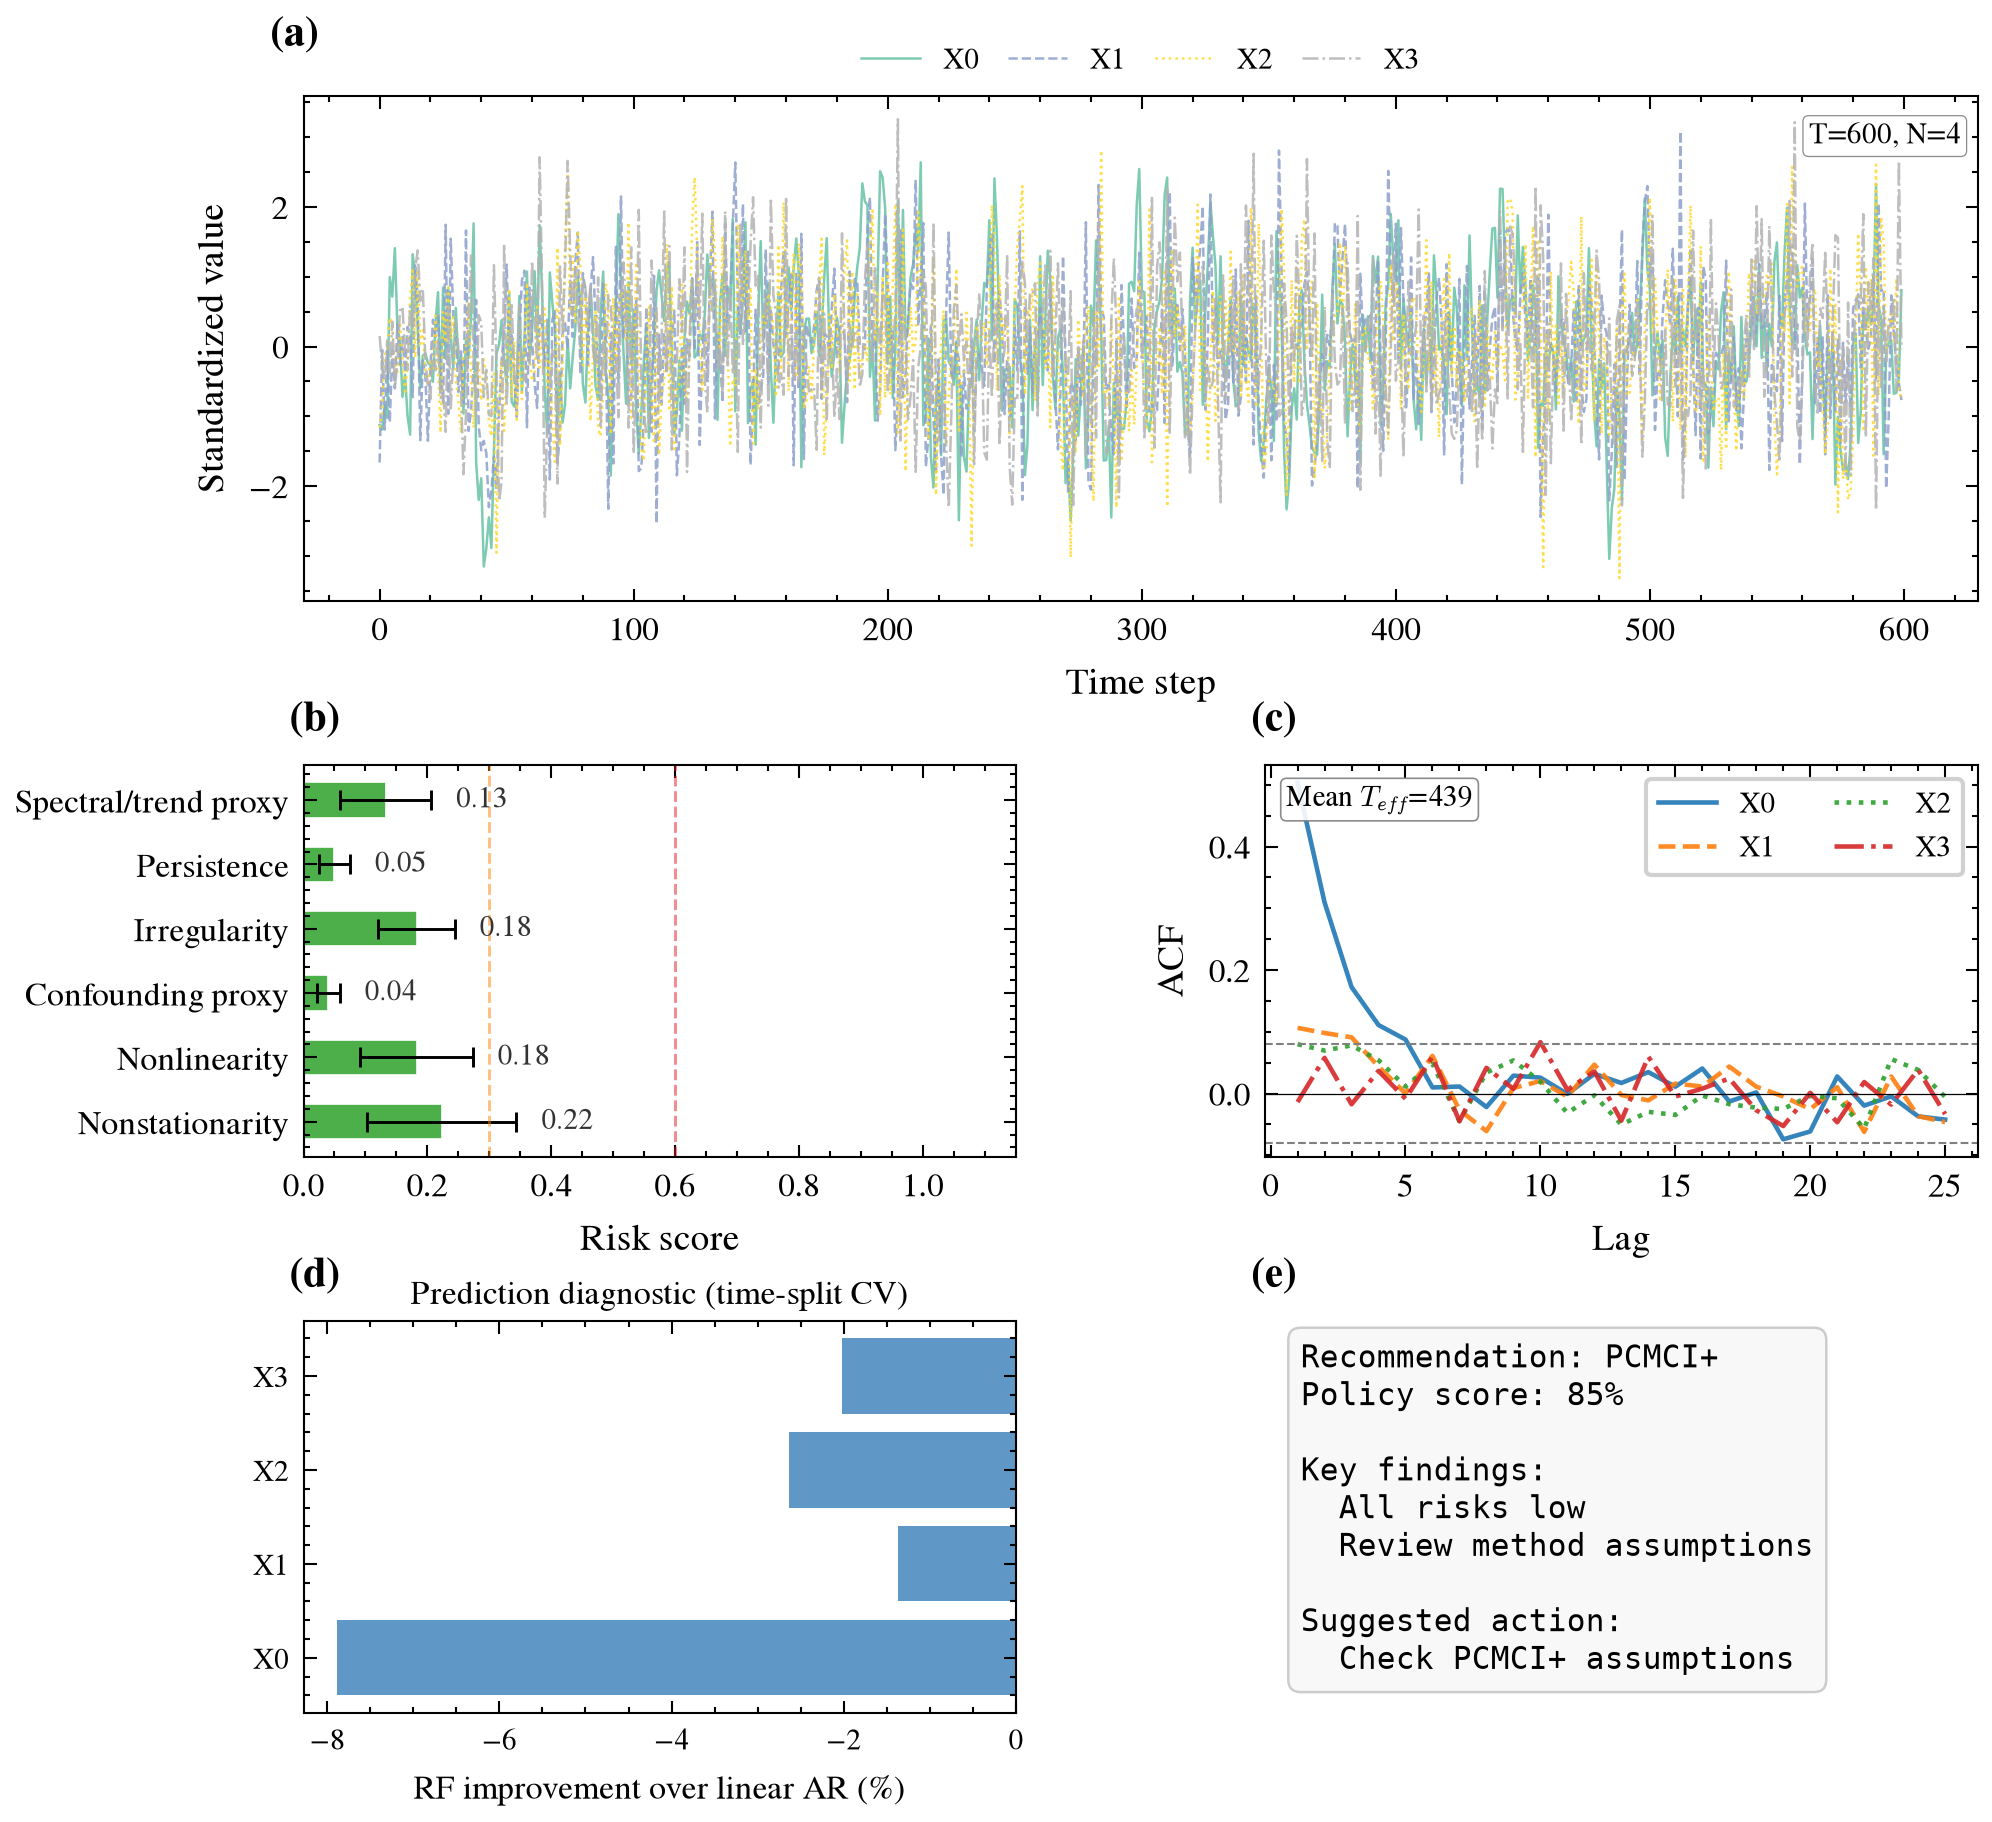

In [7]:
def show_audit_figure(audit_result, figure_name):
    figure_path = Path(audit_result["output_dir"]) / "figures" / f"{figure_name}.png"
    display(Image(filename=str(figure_path), width=950))


show_audit_figure(result, "prediscovery_summary")

## 6. Configure the audit

The same pipeline accepts these settings:

| Setting | Purpose |
| --- | --- |
| `random_seed` | Repeat randomized diagnostics. |
| `missing_value_codes` | Treat documented sentinel values as missing. |
| `method_catalog`, `priors`, `calib` | Load reviewed YAML settings; keep the files. |
| `include_dependency_network` | Opt into an exploratory PCMCI+ graph, skipped on abstention. |
| `output_dir` | Keep datasets and configurations apart. |

For data that uses `-9999` as a missing code:

```python
configured_gatekeeper = RiskAwareGatekeeper(random_seed=42)
configured_result = configured_gatekeeper.analyze(
    data=my_data,
    missing_value_codes=[-9999],
    include_dependency_network=False,
    output_dir="results/my_data_configured",
)
```

This example is meant for your data. Changing calibration files does not calibrate the audit on a new population. The proposed discovery configuration in Section 3 is separate from these audit settings.

## 7. Examine a unit root

Keep the same innovations and change only `X0`'s coefficient from 0.5 to 1.0. It becomes a random walk and the downstream variables inherit nonstationarity. No hidden cause, seasonality, or nonlinearity is added.

A coefficient of 0.99 can still be stationary. An exact unit root stays nonstationary even after the initial observations are discarded. See [VAR stationarity](https://www.statsmodels.org/stable/vector_ar.html).

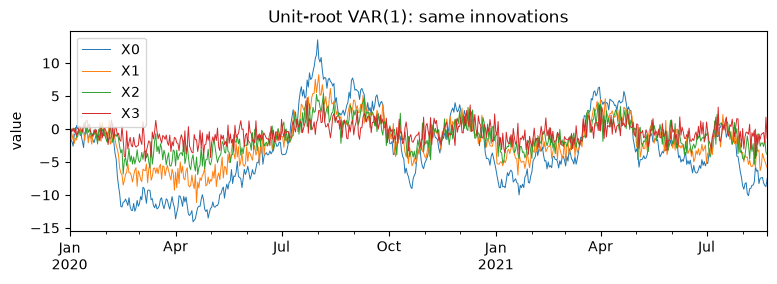

Phase 1/3: Running assumption audit...


Phase 2/3: Quantifying risks...
Phase 3/3: Generating recommendation...
Generating figures...


  ✓ Generated 6 figures (PDF + PNG, 300 DPI)

✓ Analysis complete! Results saved to walkthrough_output/unit_root
  - Decision: ABSTAIN
Decision: ABSTAIN
Reason codes: ABSTAIN, CRITICAL_NONSTATIONARITY


**Rationale**

Critical nonstationarity requires review

NonstationarityRisk=1.00 > 0.95. Investigate unit roots, structural breaks, or deterministic trends. A seasonality proxy or low nonlinearity score does not establish that deseasonalization is sufficient. Assess any preprocessing and re-audit the resulting inputs before discovery.

In [8]:
A_unit_root = A_clean.copy()
A_unit_root[0, 0] = 1.0
df_unit_root = simulate_var(A_unit_root)
ax = df_unit_root.plot(figsize=(9, 2.6), linewidth=0.7, title="Unit-root VAR(1): same innovations")
ax.set_ylabel("value")
display(ax.figure)
plt.close(ax.figure)

result_unit_root = RiskAwareGatekeeper(random_seed=42).analyze(
    data=df_unit_root, output_dir=str(output_dir / "unit_root"),
)
show_decision(result_unit_root)

### Read the second decision

The summary shows elevated risks and **ABSTAIN**, with no confidence assigned. Read the scorecard for the reason; proxy scores do not identify the mechanism.

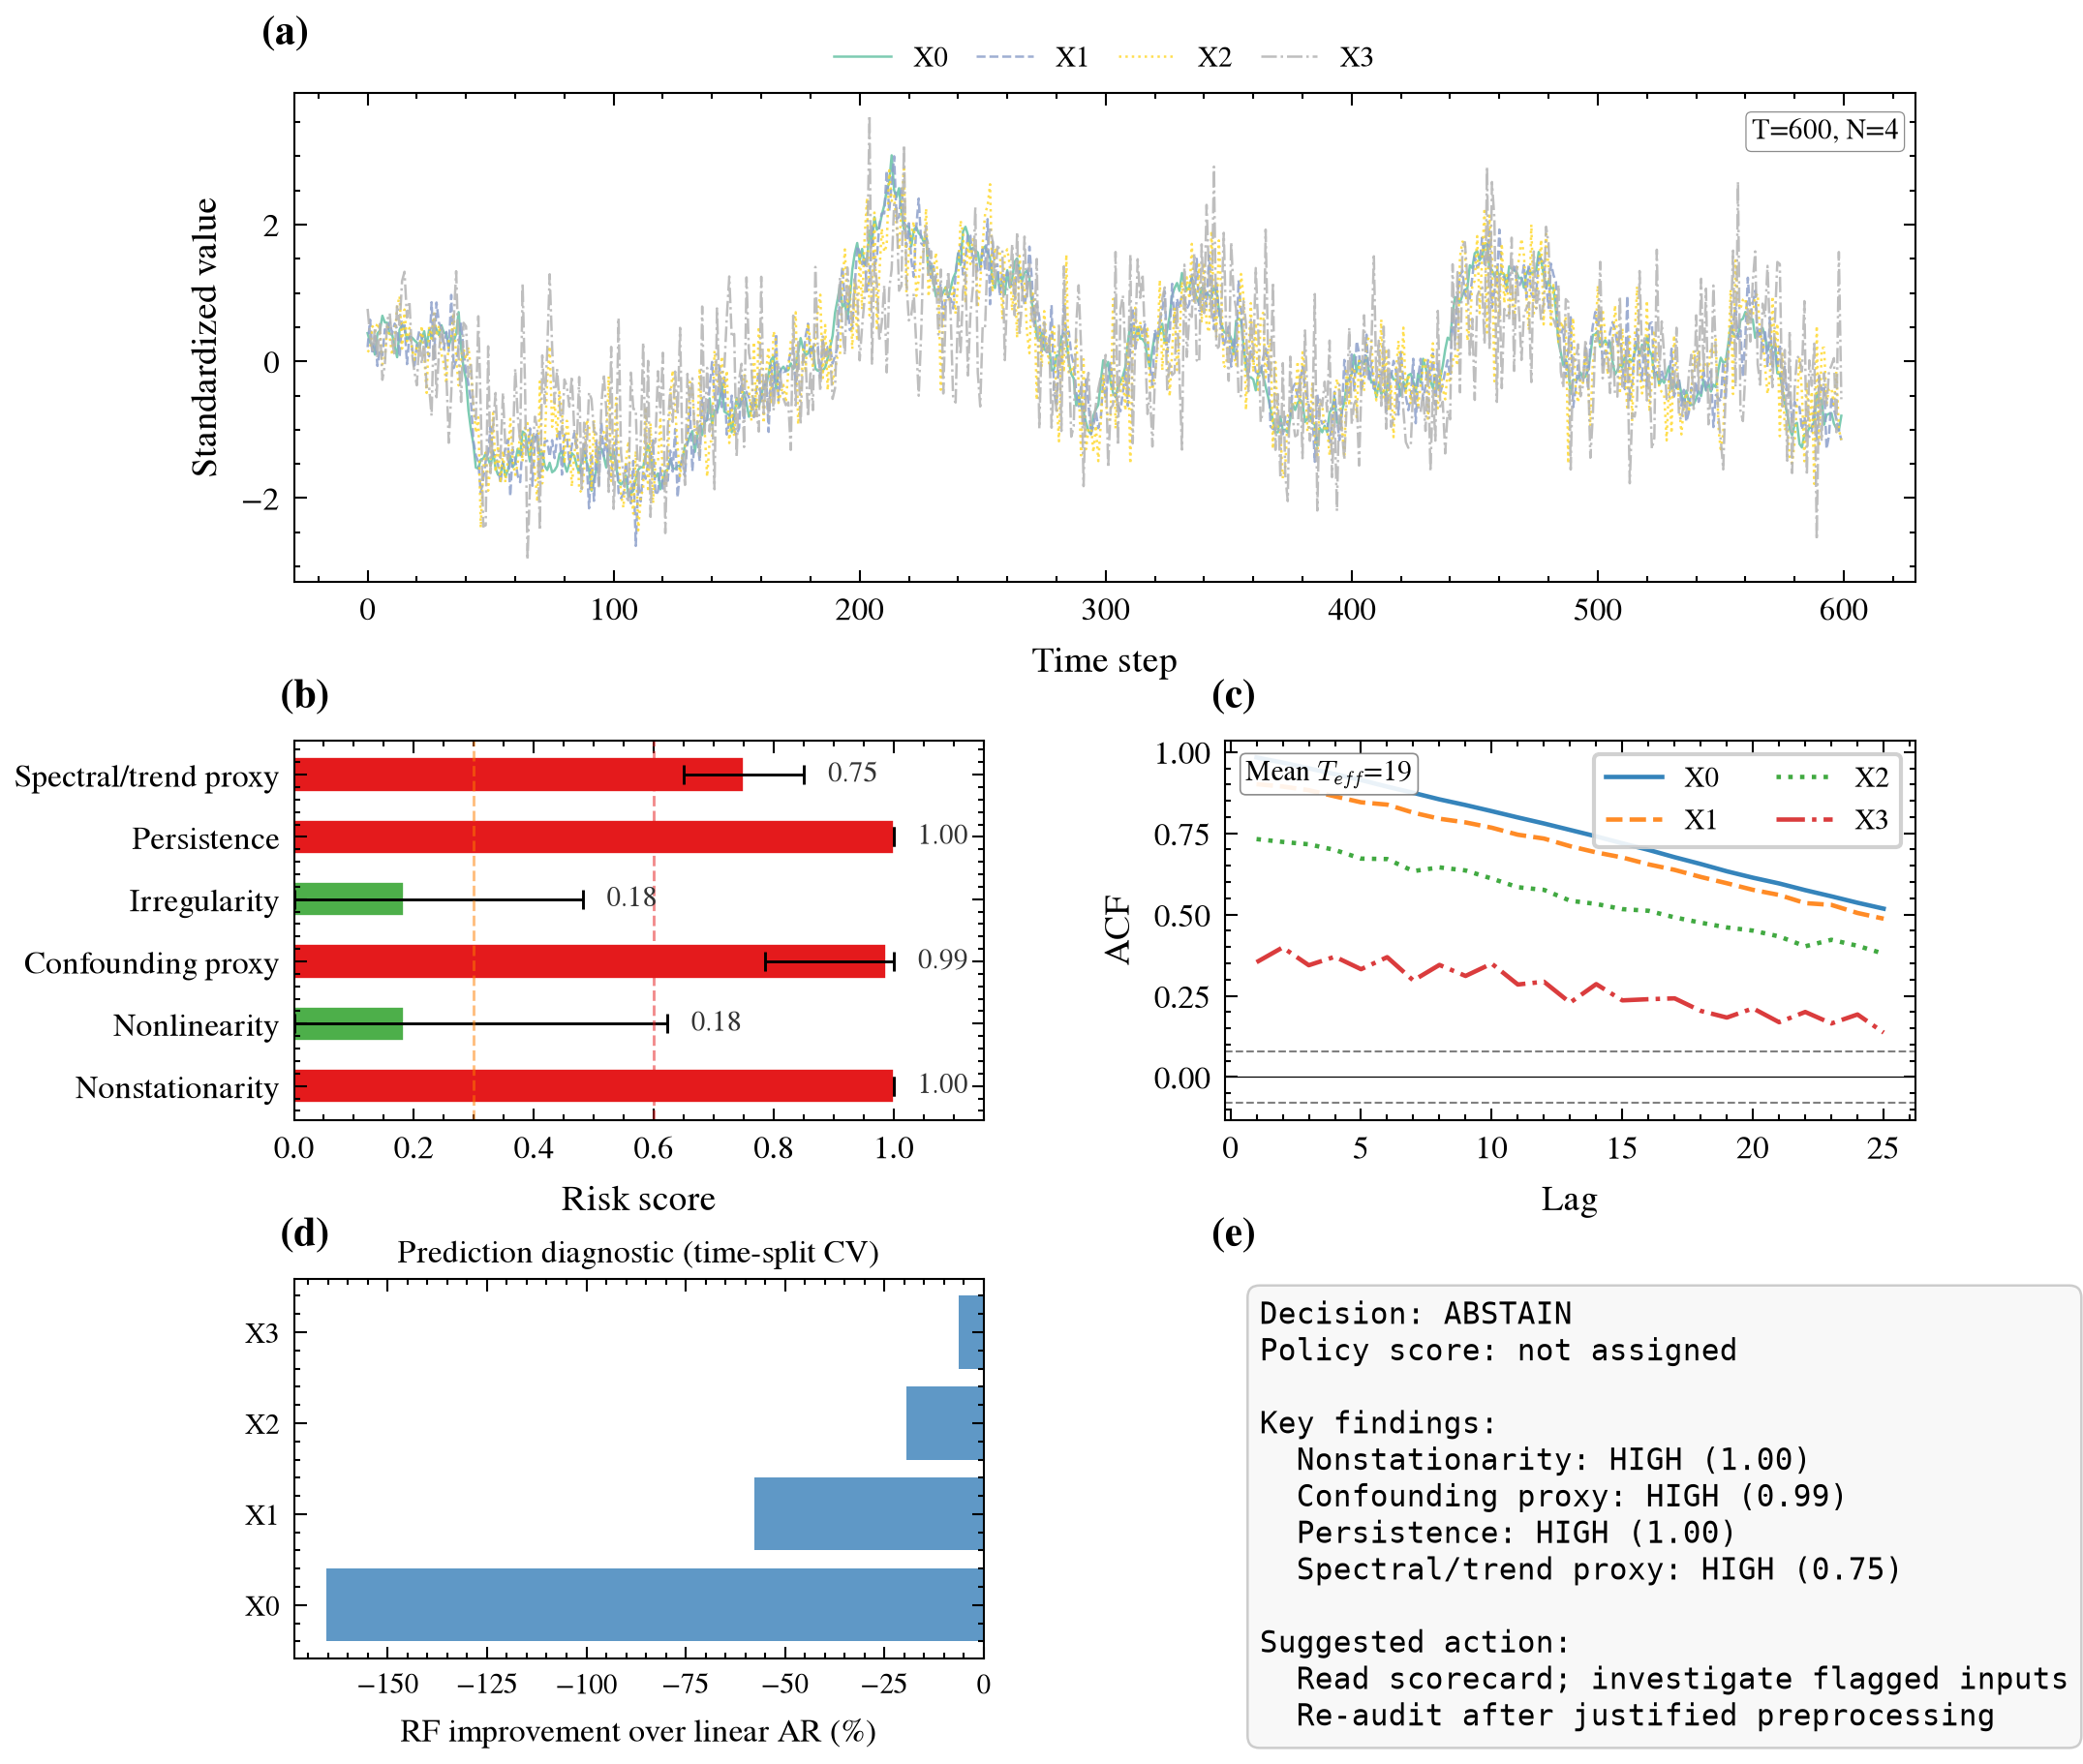

In [9]:
show_audit_figure(result_unit_root, "prediscovery_summary")

The policy abstains on severe nonstationarity, and deseasonalization does not remove a stochastic unit root.

Nonstationarity and persistence rise below. The confounding and spectral proxies rise too, because the variables share stochastic trends. This is diagnostic sensitivity, not evidence of hidden causes or periodic forcing, and one comparison does not validate calibration.

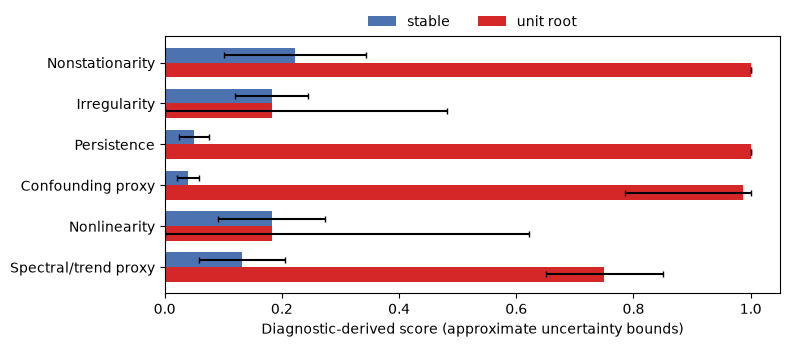

In [10]:
names = list(risk_labels)
y = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8, 3.6))
for offset, audit_result, label, color in [
    (-0.18, result, "stable", "#4C72B0"),
    (0.18, result_unit_root, "unit root", "#D62728"),
]:
    risks = audit_result["risk_profile"].risks
    scores = np.array([risks[name]["mean"] for name in names])
    errors = np.array([
        [risks[name]["mean"] - risks[name]["lower_95"] for name in names],
        [risks[name]["upper_95"] - risks[name]["mean"] for name in names],
    ])
    ax.barh(y + offset, scores, height=0.36, xerr=errors, capsize=2,
            label=label, color=color)
ax.set_yticks(y)
ax.set_yticklabels([risk_labels[name] for name in names])
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.set_xlabel("Diagnostic-derived score (approximate uncertainty bounds)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.13), ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(output_dir / "fig_risk_contrast.png", dpi=150, bbox_inches="tight")
display(fig)
plt.close(fig)

### Inspect the flagged diagnostics

The deep dive shows rolling variance, prediction gain, ESS, VIF, spectral concentration, and missingness. VIF and spectral peaks can reflect shared trends, and ESS is especially uncertain for nonstationary inputs.

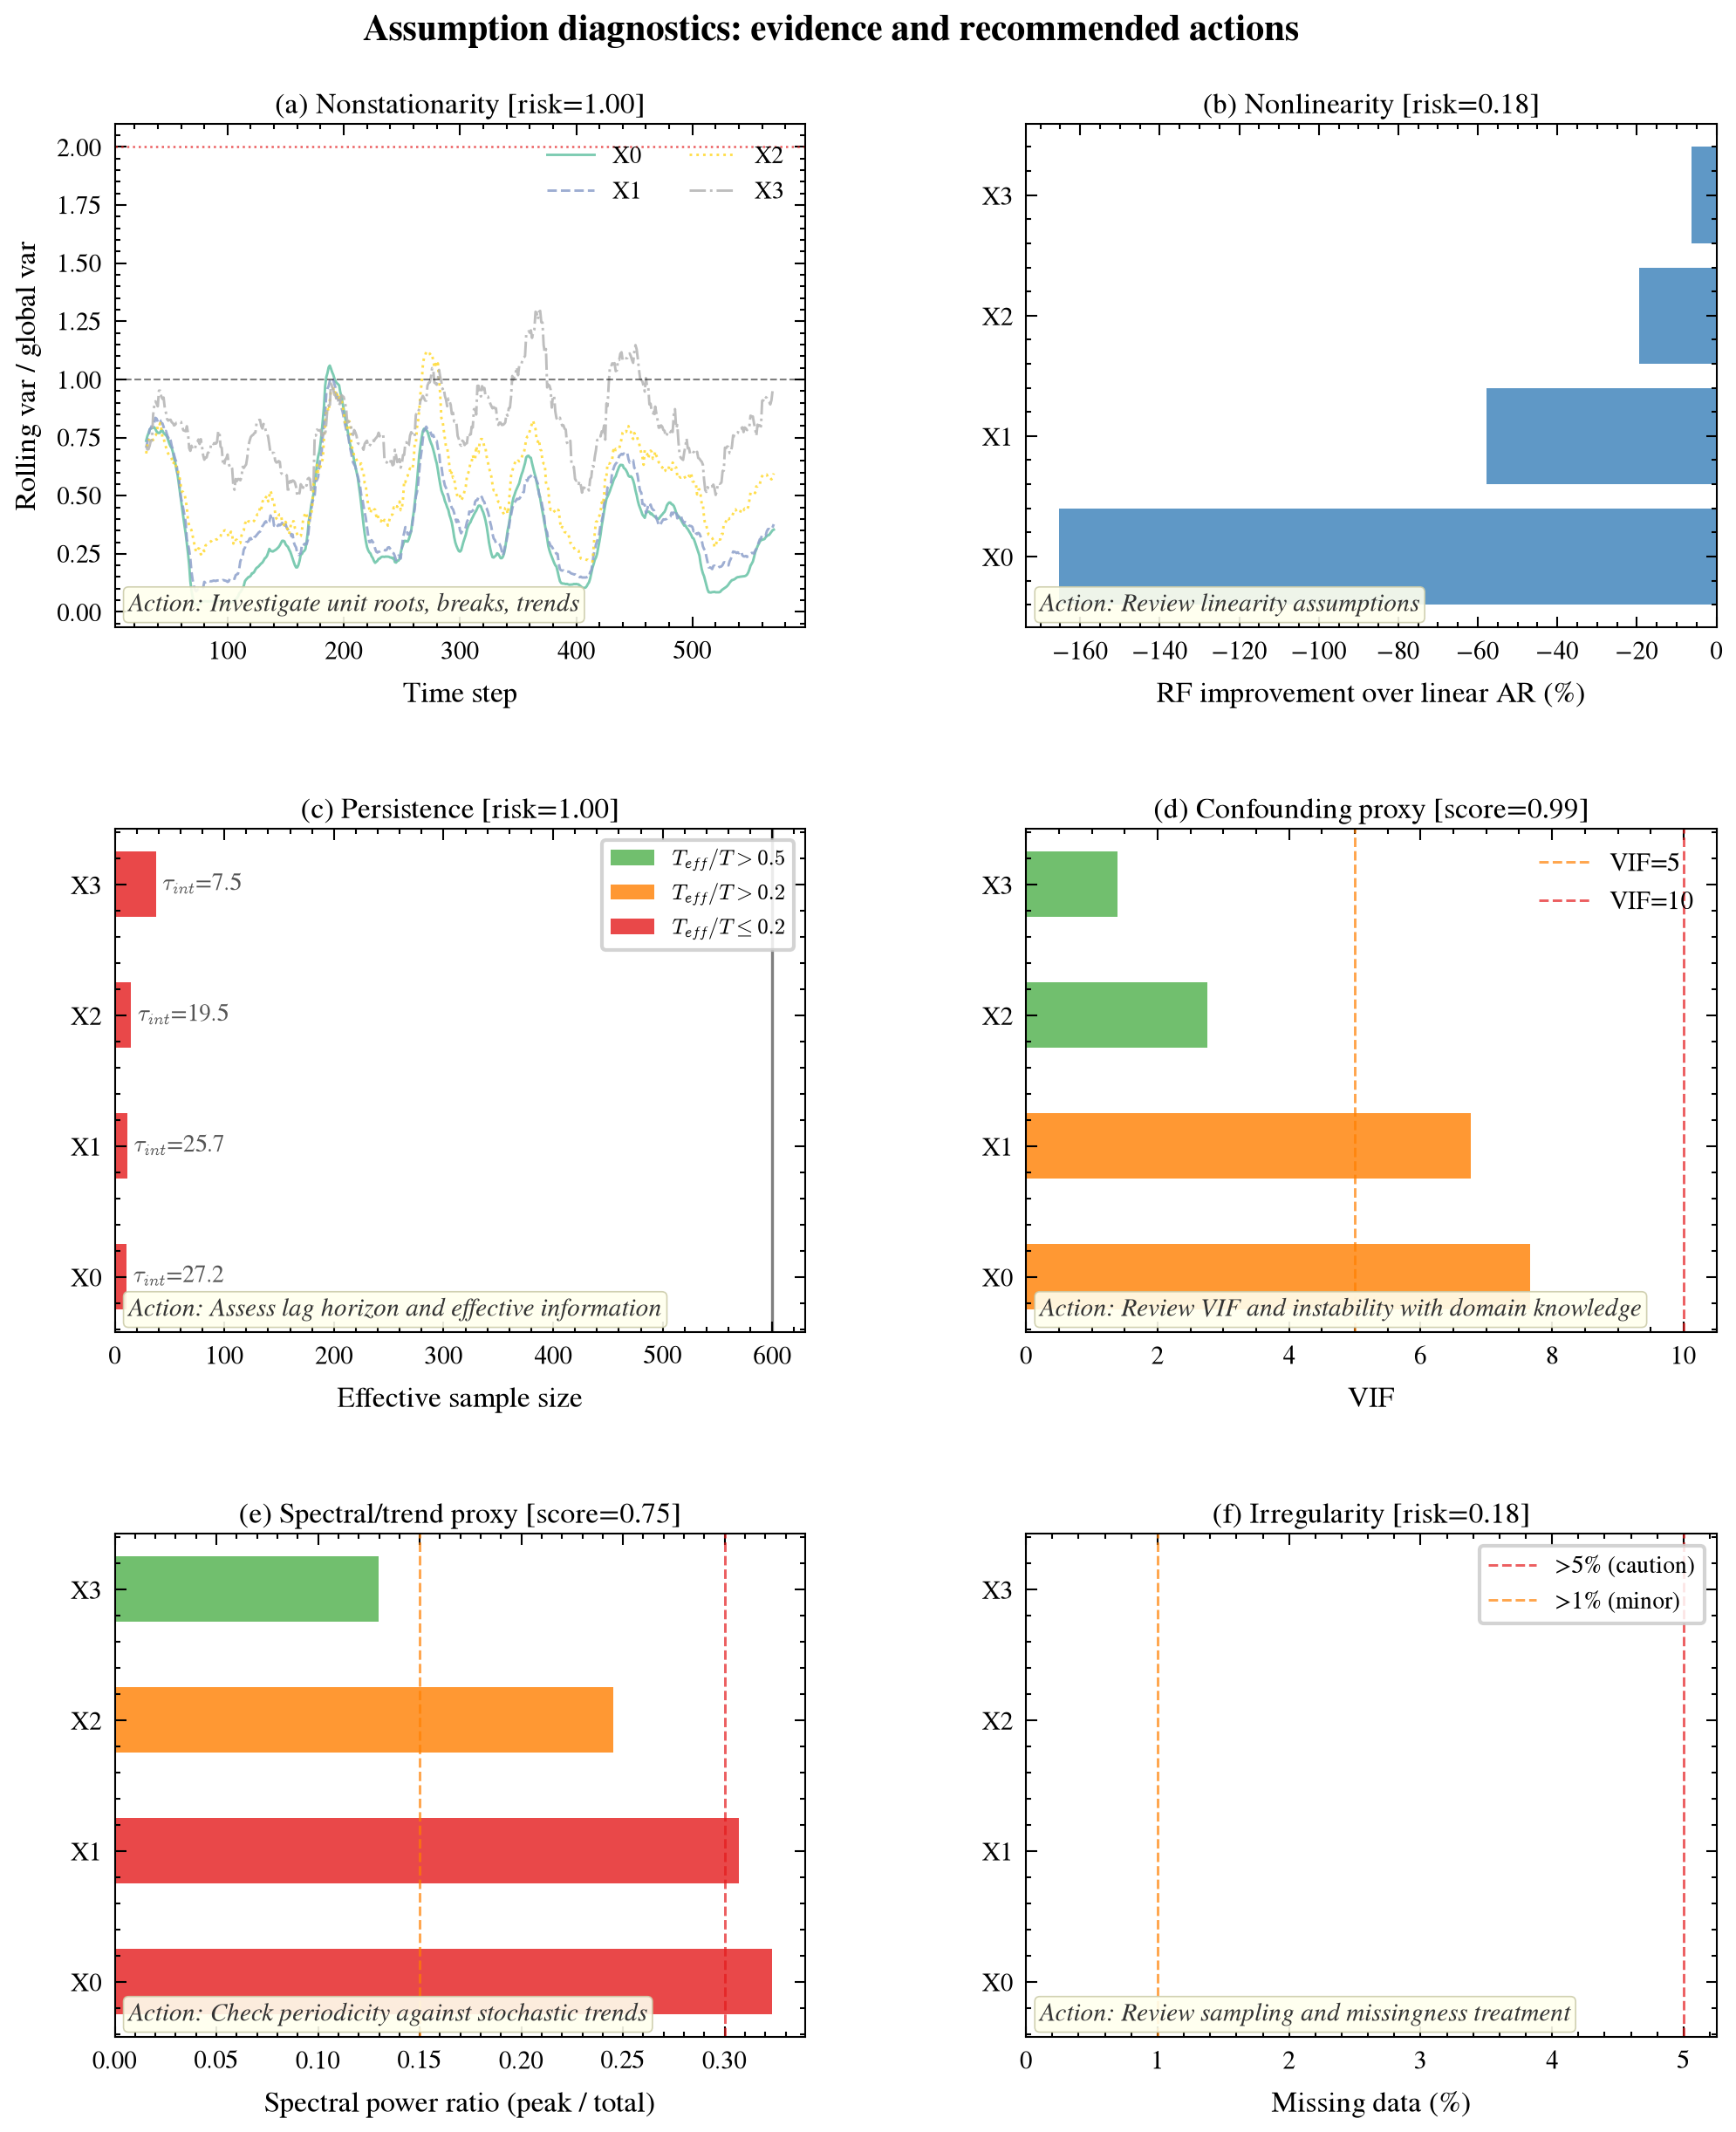

In [11]:
show_audit_figure(result_unit_root, "assumption_deep_dive")

## 8. Use your own data

After an abstention, investigate unit roots, breaks, and deterministic components. Assess preprocessing with domain knowledge, then audit the actual discovery inputs again. Differencing changes the question to relationships between changes, and cointegration may matter.

Adapt the CSV example:

```python
user_df = pd.read_csv("data.csv", parse_dates=["date"], index_col="date").sort_index()
assert isinstance(user_df.index, pd.DatetimeIndex)
assert user_df.index.is_unique, "Resolve duplicate observation times first"
assert not user_df.index.hasnans, "Resolve invalid observation times first"
assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in user_df.dtypes)

user_result = RiskAwareGatekeeper(random_seed=42).analyze(
    data=user_df,
    missing_value_codes=[-9999],  # only include codes used by your source
    output_dir="my_audit",
)
show_decision(user_result)
```

Review the proposed test, preprocessing, lag horizon, and assumptions before discovery. Scores saturated near 1 and narrow bounds do not establish certainty.

## 9. Retain the evidence

`audit_scorecard.md` holds the decision, `risk_profile.json` the scores, `audit_evidence.json` and `diagnostic_tables/` the measurements, and `recommendation_policy.json` the settings.

The cell below prints each record as a path relative to this notebook.

Keep the original data, the configuration files, the package versions, and the environment with these records.

In [12]:
clean_out = Path(result["output_dir"])
print("Clean audit records (relative to the repo root):")
for artifact in sorted(clean_out.glob("*.json")) + sorted(clean_out.glob("*.md")):
    print(" ", artifact)
unit_root_scorecard = Path(result_unit_root["output_dir"]) / "audit_scorecard.md"
print("Unit-root scorecard:", unit_root_scorecard)


Clean audit records (relative to the repo root):
  walkthrough_output/clean/audit_evidence.json
  walkthrough_output/clean/recommendation_policy.json
  walkthrough_output/clean/risk_profile.json
  walkthrough_output/clean/audit_scorecard.md
  walkthrough_output/clean/audit_summary.md
  walkthrough_output/clean/risk_summary.md
Unit-root scorecard: walkthrough_output/unit_root/audit_scorecard.md


For optional figures and deeper implementation details, see [FRAMEWORK.md](../causal_audit/FRAMEWORK.md). The per-stage API is documented in the [README](../README.md); use the gatekeeper for the complete configured pipeline.